In [61]:
import xarray as xr
import math
import os
import numpy as np
import matplotlib.pyplot as plt 

In [62]:
filename = "./data/PECD/H_ERA5_ECMW_T639_GHI_0000m_Pecd_025d_S202501010000_E202512312300_INS_MAP_01h_COM_noc_org_NA_NA---_NA---_NA---_PECD4.2_fv1.nc"
input_dir = ""
file_path = os.path.join(input_dir, filename)
# open file, chunk along time dimension to improve performance
ds1 = xr.open_dataset(file_path)

In [63]:
ds1

<xarray.Dataset> Size: 5GB
Dimensions:    (time: 8760, latitude: 229, longitude: 305)
Coordinates:
  * time       (time) datetime64[ns] 70kB 2025-01-01 ... 2025-12-31T23:00:00
  * latitude   (latitude) float64 2kB 75.0 74.75 74.5 74.25 ... 18.5 18.25 18.0
  * longitude  (longitude) float64 2kB -31.0 -30.75 -30.5 ... 44.5 44.75 45.0
Data variables:
    ssrd       (time, latitude, longitude) float64 5GB ...
Attributes:
    title:        Surface solar radiation downwards; data for ENTSO-E PECD Ve...
    institution:  Copernicus Climate Change Service, Sectoral Information Sys...
    source:       ERA5 reanalysis data provided by ECMWF (https://www.ecmwf.i...
    history:      2026-02-11 14:42:21 GMT by write_hist_xr_to_nc-0.1.dev28+gf...
    references:   
    Conventions:  CF-1.12-draft

In [64]:
input_folder = "./data/MERRA-2-rad" 
files_pattern = os.path.join(input_folder, "MERRA2_400.tavg1_2d_rad_Nx.2025*.nc")

ds2 = xr.open_mfdataset(
    files_pattern,
    combine="by_coords",
    chunks={"time": 24}
)

In [65]:
ds2

<xarray.Dataset> Size: 44GB
Dimensions:      (time: 8760, lat: 228, lon: 304)
Coordinates:
  * time         (time) datetime64[ns] 70kB 2025-01-01T00:30:00 ... 2025-12-3...
  * lat          (lat) float64 2kB 18.12 18.38 18.62 18.88 ... 74.38 74.62 74.88
  * lon          (lon) float64 2kB -30.88 -30.62 -30.38 ... 44.38 44.62 44.88
Data variables: (12/18)
    LWGEM        (time, lat, lon) float32 2GB dask.array<chunksize=(24, 215, 304), meta=np.ndarray>
    LWGNT        (time, lat, lon) float32 2GB dask.array<chunksize=(24, 215, 304), meta=np.ndarray>
    LWGNTCLR     (time, lat, lon) float32 2GB dask.array<chunksize=(24, 215, 304), meta=np.ndarray>
    LWGNTCLRCLN  (time, lat, lon) float32 2GB dask.array<chunksize=(24, 215, 304), meta=np.ndarray>
    LWTUP        (time, lat, lon) float32 2GB dask.array<chunksize=(24, 215, 304), meta=np.ndarray>
    LWTUPCLR     (time, lat, lon) float32 2GB dask.array<chunksize=(24, 215, 304), meta=np.ndarray>
    ...           ...
    SWGNTCLRCLN  (time, lat, lon) float32 2GB dask.array<chunksize=(24, 215, 304), meta=np.ndarray>
    SWTDN        (time, lat, lon) float32 2GB dask.array<chunksize=(24, 215, 304), meta=np.ndarray>
    SWTNT        (time, lat, lon) float32 2GB dask.array<chunksize=(24, 215, 304), meta=np.ndarray>
    SWTNTCLN     (time, lat, lon) float32 2GB dask.array<chunksize=(24, 215, 304), meta=np.ndarray>
    SWTNTCLR     (time, lat, lon) float32 2GB dask.array<chunksize=(24, 215, 304), meta=np.ndarray>
    SWTNTCLRCLN  (time, lat, lon) float32 2GB dask.array<chunksize=(24, 215, 304), meta=np.ndarray>
Attributes: (12/32)
    CDI:                               Climate Data Interface version 1.9.8 (...
    Conventions:                       CF-1
    History:                           Original file generated: Sat Jan 11 20...
    Comment:                           GMAO filename: d5124_m2_jan10.tavg1_2d...
    Filename:                          MERRA2_400.tavg1_2d_rad_Nx.20250101.nc4
    Institution:                       NASA Global Modeling and Assimilation ...
    ...                                ...
    RangeBeginningDate:                2025-01-01
    RangeBeginningTime:                00:00:00.000000
    RangeEndingDate:                   2025-01-01
    RangeEndingTime:                   23:59:59.000000
    history_L34RS:                     'Created by L34RS v1.4.4 @ NASA GES DI...
    CDO:                               Climate Data Operators version 1.9.8 (...

In [66]:
ds1 = ds1.rename({"latitude": "lat", "longitude": "lon"})

In [67]:
ds2 = ds2.assign_coords(time=ds2.time - np.timedelta64(30, "m"))

In [68]:
ds2_on_ds1 = ds2.interp(
    lat=ds1.lat,
    lon=ds1.lon,
    method="nearest"
)

In [69]:
ds1, ds2_on_ds1 = xr.align(ds1, ds2_on_ds1, join="inner")

In [70]:
residual = ds2_on_ds1["SWGDN"] - ds1["ssrd"]

In [71]:
residual_mean = residual.mean(dim="time")

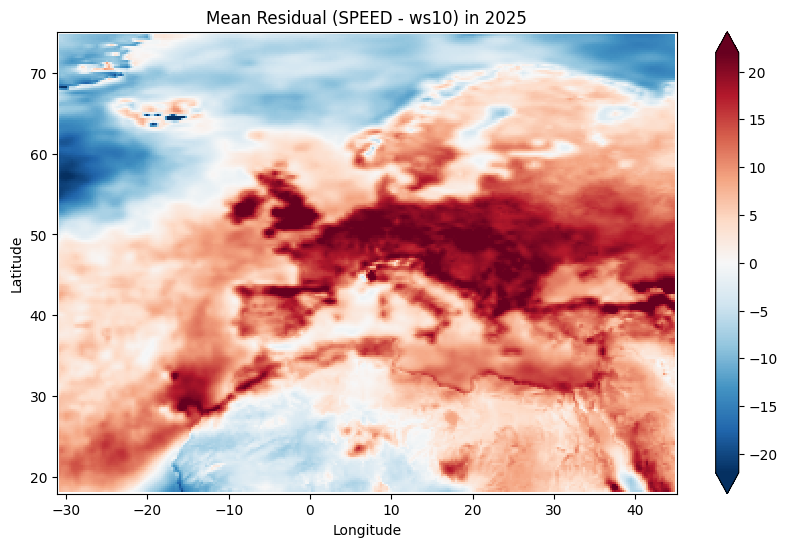

In [72]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

residual_mean.plot(
    cmap="RdBu_r",   # good for positive/negative differences
    robust=True      # avoids extreme outliers dominating color scale
)

plt.title("Mean Residual (SPEED - ws10) in 2025")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

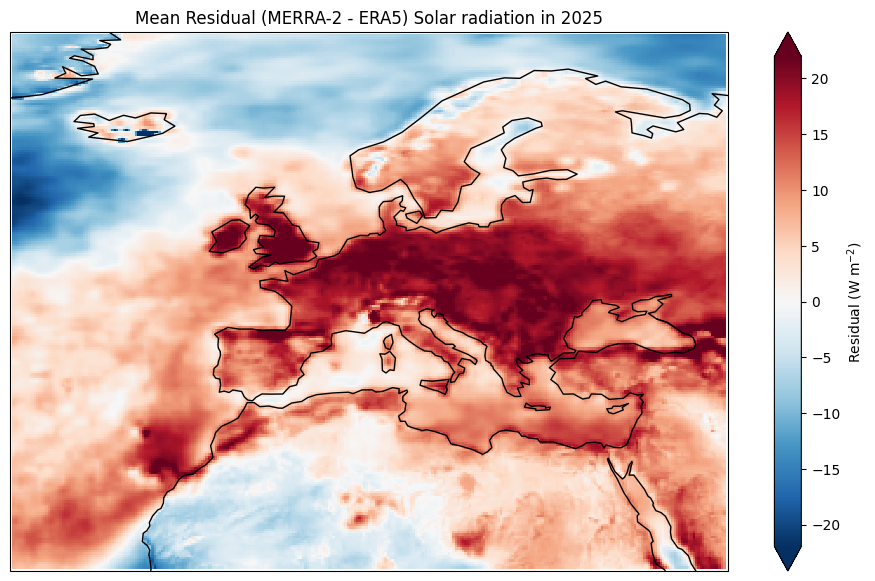

In [73]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

fig = plt.figure(figsize=(12, 7))
ax = plt.axes(projection=ccrs.PlateCarree())

residual_mean.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    robust=True,
    cbar_kwargs={"label": "Residual (W m$^{-2}$)"}
)

ax.coastlines()
ax.set_title("Mean Residual (MERRA-2 - ERA5) Solar radiation in 2025")

plt.show()

In [5]:
# Plot felix

In [7]:
import xarray as xr
import math
import os
import numpy as np
import matplotlib.pyplot as plt 
import pandas as pd
import glob

In [8]:
import xarray as xr
import pandas as pd
import glob

# path to all files
files = sorted(glob.glob("./data/MERRA-2-2015-2025/*.nc"))

# open all datasets at once
ds = xr.open_mfdataset(files, combine="by_coords", chunks={"time": 24})

# compute global mean (lat, lon)
ds_mean = ds[["SPEED", "TLML"]].mean(dim=["lat", "lon"])

# group by year and average
ds_yearly = ds_mean.groupby("time.year").mean()

# convert to dataframe
df = ds_yearly.to_dataframe().reset_index()

print(df.head())

   year     SPEED        TLML
0  2015  7.424267  285.478668
1  2016  7.185468  285.745148
2  2017  7.222804  285.563873
3  2018  7.248813  285.734528
4  2019  7.204211  285.702911


In [9]:
import numpy as np

weights = np.cos(np.deg2rad(ds.lat))
weights.name = "weights"

ds_weighted = ds[["SPEED", "TLML"]].weighted(weights)

ds_mean = ds_weighted.mean(dim=["lat", "lon"])
ds_yearly = ds_mean.groupby("time.year").mean()

df = ds_yearly.to_dataframe().reset_index()

In [10]:
df

,year,SPEED,TLML
0,2015,7.150145,288.042109
1,2016,6.990196,288.256783
2,2017,6.989293,288.144142
3,2018,7.026156,288.282166
4,2019,7.002786,288.292127
5,2020,7.108816,288.395495
6,2021,6.972270,288.341255
7,2022,7.063829,288.506165
8,2023,6.960456,288.828959
9,2024,7.027715,288.974166


In [11]:
df["TLML"] = df["TLML"] - 273.15

In [12]:
df

,year,SPEED,TLML
0,2015,7.150145,14.892109
1,2016,6.990196,15.106783
2,2017,6.989293,14.994142
3,2018,7.026156,15.132166
4,2019,7.002786,15.142127
5,2020,7.108816,15.245495
6,2021,6.972270,15.191255
7,2022,7.063829,15.356165
8,2023,6.960456,15.678959
9,2024,7.027715,15.824166


In [13]:
df_yearly_mean = df

In [14]:
df = df_yearly_mean

In [15]:
import xarray as xr
import numpy as np
import pandas as pd
import glob
import os

input_dir = "./data/MERRA-2-rad-2015-2025"
files = sorted(glob.glob(os.path.join(input_dir, "*.nc")))

swgdn_results = []

for f in files:
    ds_rad = xr.open_dataset(f, chunks={"time": 24})
    
    # extract year
    year = int(ds_rad.time.dt.year.values[0])    
    # latitude weights
    weights = np.cos(np.deg2rad(ds_rad.lat))
    weights.name = "weights"
    
    # weighted spatial mean
    da_weighted = ds_rad["SWGDN"].weighted(weights)
    spatial_mean = da_weighted.mean(dim=["lat", "lon"])
    
    # yearly mean
    yearly_mean = spatial_mean.mean(dim="time").compute()
    
    swgdn_results.append({
        "year": year,
        "SWGDN": float(yearly_mean.values)
    })

# convert to DataFrame
df_swgdn = pd.DataFrame(swgdn_results)

# aggregate daily → yearly mean
df_swgdn = df_swgdn.groupby("year", as_index=False)["SWGDN"].mean()
# merge with your existing dataframe
df = df.merge(df_swgdn, on="year")

In [16]:
df

,year,SPEED,TLML,SWGDN
0,2015,7.150145,14.892109,189.403462
1,2016,6.990196,15.106783,189.175636
2,2017,6.989293,14.994142,190.478763
3,2018,7.026156,15.132166,189.011558
4,2019,7.002786,15.142127,192.144807
5,2020,7.108816,15.245495,190.622397
6,2021,6.972270,15.191255,189.787692
7,2022,7.063829,15.356165,190.497109
8,2023,6.960456,15.678959,190.777220
9,2024,7.027715,15.824166,189.559611


In [17]:
import xarray as xr
import numpy as np
import pandas as pd
import glob
import os

input_dir = "./data/ERA-5-2014-2025"
files = sorted(glob.glob(os.path.join(input_dir, "*.nc")))

results = []

for f in files:
    ds_er = xr.open_dataset(f, chunks={"time": 1000})
    
    # get variable name automatically (only one data variable per file)
    print(ds_er.data_vars)
    var_name = list(ds_er.data_vars)[0]
    
    # extract year from time coordinate
    year_er = int(ds_er.time.dt.year.values[0])
    
    # latitude weighting (IMPORTANT for global mean)
    weights_er = np.cos(np.deg2rad(ds_er.latitude))
    weights_er.name = "weights"
    
    # weighted spatial mean
    da_weighted_er = ds_er[var_name].weighted(weights_er)
    spatial_mean_er = da_weighted_er.mean(dim=["latitude", "longitude"])
    
    # yearly mean (mean over time dimension)
    yearly_mean_er = spatial_mean_er.mean(dim="time").compute()
    
    results.append({
        "year": year_er,
        "variable": var_name,
        "value": float(yearly_mean_er.values)
    })

# convert to dataframe
df_er = pd.DataFrame(results)

print(df_er.head())

Data variables:
    ssrd     (time, latitude, longitude) float64 5GB dask.array<chunksize=(1000, 229, 305), meta=np.ndarray>
Data variables:
    ssrd     (time, latitude, longitude) float64 5GB dask.array<chunksize=(1000, 229, 305), meta=np.ndarray>
Data variables:
    ssrd     (time, latitude, longitude) float64 5GB dask.array<chunksize=(1000, 229, 305), meta=np.ndarray>
Data variables:
    ssrd     (time, latitude, longitude) float64 5GB dask.array<chunksize=(1000, 229, 305), meta=np.ndarray>
Data variables:
    ssrd     (time, latitude, longitude) float64 5GB dask.array<chunksize=(1000, 229, 305), meta=np.ndarray>
Data variables:
    ssrd     (time, latitude, longitude) float64 5GB dask.array<chunksize=(1000, 229, 305), meta=np.ndarray>
Data variables:
    ssrd     (time, latitude, longitude) float64 5GB dask.array<chunksize=(1000, 229, 305), meta=np.ndarray>
Data variables:
    ssrd     (time, latitude, longitude) float64 5GB dask.array<chunksize=(1000, 229, 305), meta=np.ndarray>


In [18]:
df_er

,year,variable,value
0,2014,ssrd,185.083303
1,2015,ssrd,184.774106
2,2016,ssrd,183.719050
3,2017,ssrd,185.692718
4,2018,ssrd,184.744241
5,2019,ssrd,185.712818
6,2020,ssrd,185.938894
7,2021,ssrd,186.406244
8,2022,ssrd,186.366139
9,2023,ssrd,186.329494


In [19]:
# Pivot the long df_er to wide format
df_er_wide = df_er.pivot(index="year", columns="variable", values="value").reset_index()

# Rename columns to match your MERRA DataFrame
df_er_wide = df_er_wide.rename(columns={
    "t2m": "TLML",       # temperature
    "ws10": "SPEED",     # wind speed
    "ssrd": "SWGDN"      # radiation
})

# Convert temperature to Celsius
df_er_wide["TLML"] = df_er_wide["TLML"] - 273.15

# Reorder columns to match: year, SPEED, TLML, SWGDN
df_er_wide = df_er_wide[["year", "SPEED", "TLML", "SWGDN"]]

In [20]:
df_er_wide

variable,year,SPEED,TLML,SWGDN
0,2014,5.322130,15.682934,185.083303
1,2015,5.407064,15.539686,184.774106
2,2016,5.297404,15.760987,183.719050
3,2017,5.292426,15.606300,185.692718
4,2018,5.343008,15.749971,184.744241
5,2019,5.316981,15.690521,185.712818
6,2020,5.378388,15.887469,185.938894
7,2021,5.286963,15.772339,186.406244
8,2022,5.337607,15.867120,186.366139
9,2023,5.237780,16.176151,186.329494


In [21]:
df

,year,SPEED,TLML,SWGDN
0,2015,7.150145,14.892109,189.403462
1,2016,6.990196,15.106783,189.175636
2,2017,6.989293,14.994142,190.478763
3,2018,7.026156,15.132166,189.011558
4,2019,7.002786,15.142127,192.144807
5,2020,7.108816,15.245495,190.622397
6,2021,6.972270,15.191255,189.787692
7,2022,7.063829,15.356165,190.497109
8,2023,6.960456,15.678959,190.777220
9,2024,7.027715,15.824166,189.559611


In [22]:
# drop row 5 by index
df = df.drop(6).reset_index(drop=True)

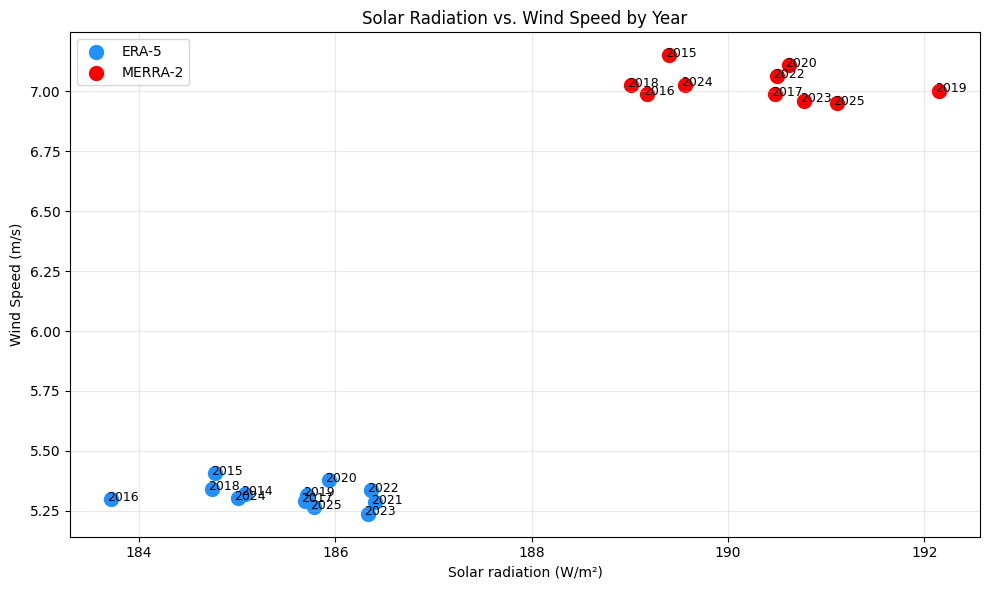

In [23]:
import matplotlib.pyplot as plt

# Use your wide-format df
df_plot_era = df_er_wide
df_plot_merra = df

plt.figure(figsize=(10,6))

# Scatter for ERA5
plt.scatter(
    df_plot_era["SWGDN"],
    df_plot_era["SPEED"],
    color="dodgerblue",
    s=100,
    label="ERA-5"
)

# Scatter for MERRA-2
plt.scatter(
    df_plot_merra["SWGDN"],
    df_plot_merra["SPEED"],
    color="red",
    s=100,
    label="MERRA-2"
)

# Annotate each point with year (ERA5)
for i, row in df_plot_era.iterrows():
    plt.text(row["SWGDN"] - 0.04, row["SPEED"] - 0.007, str(int(row["year"])), fontsize=9)

# Annotate each point with year (MERRA-2)
for i, row in df_plot_merra.iterrows():
    plt.text(row["SWGDN"] - 0.04, row["SPEED"] - 0.007, str(int(row["year"])), fontsize=9)

plt.xlabel("Solar radiation (W/m²)")
plt.ylabel("Wind Speed (m/s)")
plt.title("Solar Radiation vs. Wind Speed by Year")
plt.grid(alpha=0.3)
plt.legend()  # <-- adds the legend
plt.tight_layout()
plt.show()